# PCA Analysis of Dissolved Oxygen

This notebook performs Principal Component Analysis (PCA) on the spatially interpolated DO data from `09_Spatial_Interpolation_v2.ipynb`.

**Objective**: Identify dominant spatial and temporal patterns in DO variability across stations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("..").resolve()
sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Interpolated Data

In [3]:
# Load interpolated DO data from 09_Spatial_Interpolation_v2.ipynb
interpolated_do_df = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / "interpolated_do_df.csv", index_col=0)
interpolated_do_df.index = interpolated_do_df.index.astype(str).str.zfill(8)

print(f"Interpolated DO shape: {interpolated_do_df.shape}")
print(f"Remaining NaN values: {interpolated_do_df.isna().sum().sum()}")
interpolated_do_df.head()

Interpolated DO shape: (127, 42)
Remaining NaN values: 101


,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
00000272,2.6,4.0,1.500000,1.1,1.9,2.1,0.800000,2.9,2.1,1.5,...,1.7,NaN,NaN,0.600000,0.700000,1.1,1.1,0.8,1.1,NaN
00000275,3.7,1.1,3.174373,1.5,0.7,3.1,3.197146,1.1,1.4,0.3,...,0.5,4.263147,0.6,2.787423,2.193118,0.6,0.8,2.3,0.6,4.476504
00002725,7.9,5.6,5.400000,4.8,3.9,9.5,6.200000,5.0,5.5,5.9,...,5.7,6.200000,6.1,5.900000,2.900000,6.6,6.6,3.1,6.4,6.500000
00002737,8.3,6.8,5.600000,5.4,5.1,6.6,6.000000,4.7,6.0,4.6,...,6.7,6.500000,5.5,6.000000,6.200000,6.1,7.6,6.9,5.3,4.900000
00002744,7.7,6.6,6.800000,3.6,4.8,5.8,5.800000,5.5,5.6,6.4,...,6.2,5.900000,6.3,5.800000,6.700000,6.2,6.5,6.0,6.1,6.400000


## 2. Prepare Data for PCA

PCA requires complete data (no NaN). We drop any stations still containing missing values after interpolation.

In [4]:
# Drop stations with remaining NaN values
pca_ready_df = interpolated_do_df.dropna(axis=0, how='any')

print(f"Stations retained for PCA: {len(pca_ready_df)} / {len(interpolated_do_df)}")
print(f"Years: {len(pca_ready_df.columns)}")

# Transpose: rows = years (samples), columns = stations (features)
data_matrix = pca_ready_df.T
print(f"\nData matrix shape (years x stations): {data_matrix.shape}")

Stations retained for PCA: 121 / 127
Years: 42

Data matrix shape (years x stations): (42, 121)


In [5]:
# --- CONFIGURATION ---
# Set to True to use Standardized data (mean=0, std=1)
# Set to False to use Raw data (preserving magnitude)
USE_STANDARDIZED_DATA = False 

# 1. Standardize the data (we compute this always, but only use if selected)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_matrix)

# 2. Select the dataset for PCA
if USE_STANDARDIZED_DATA:
    pca_input_data = scaled_data
    print(f"--> MODE: Using STANDARDIZED Data for PCA.")
    print("    (Focuses on correlation patterns; gives rare stations equal weight)")
else:
    pca_input_data = data_matrix
    print(f"--> MODE: Using RAW Data for PCA.")
    print("    (Preserves absolute magnitude variations)")

print(f"Input Data Shape: {pca_input_data.shape}")

--> MODE: Using RAW Data for PCA.
    (Preserves absolute magnitude variations)
Input Data Shape: (42, 121)


## 3. Perform PCA

In [6]:
# Perform PCA on the selected data
pca = PCA()
pca_scores = pca.fit_transform(pca_input_data)  # transformed data (time series)

# Calculate Explained Variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# --- SAVE RESULTS ---
# 1. Temporal Scores (PC1, PC2... over Time)
# Row Index = Years (from pca_ready_df.columns), Columns = PCs
scores_df = pd.DataFrame(
    pca_scores,
    index=pca_ready_df.columns,  # Years
    columns=[f"PC{i+1}" for i in range(len(pca_scores[0]))]
)

# 2. Spatial Loadings (Contribution of each Station to PCs)
# Row Index = PCs, Columns = Station IDs (from pca_ready_df.index)
# Note: pca.components_ shape is (n_components, n_features)
loadings_df = pd.DataFrame(
    pca.components_,
    index=[f"PC{i+1}" for i in range(len(pca_scores[0]))],
    columns=pca_ready_df.index  # Station IDs
)

print(f"PCA performed successfully.")
print(f"Scores DataFrame: {scores_df.shape} (Rows=Years)")
print(f"Loadings DataFrame: {loadings_df.shape} (Columns=Stations)")

print(f"\nTop 5 PC Explained Variance:")
for i in range(5):
    print(f"  PC{i+1}: {explained_variance[i]*100:.2f}% (Cumulative: {cumulative_variance[i]*100:.2f}%)")

PCA performed successfully.
Scores DataFrame: (42, 42) (Rows=Years)
Loadings DataFrame: (42, 121) (Columns=Stations)

Top 5 PC Explained Variance:
  PC1: 16.26% (Cumulative: 16.26%)
  PC2: 9.39% (Cumulative: 25.65%)
  PC3: 6.90% (Cumulative: 32.55%)
  PC4: 5.85% (Cumulative: 38.41%)
  PC5: 5.65% (Cumulative: 44.06%)


## 4. Scree Plot (Explained Variance)

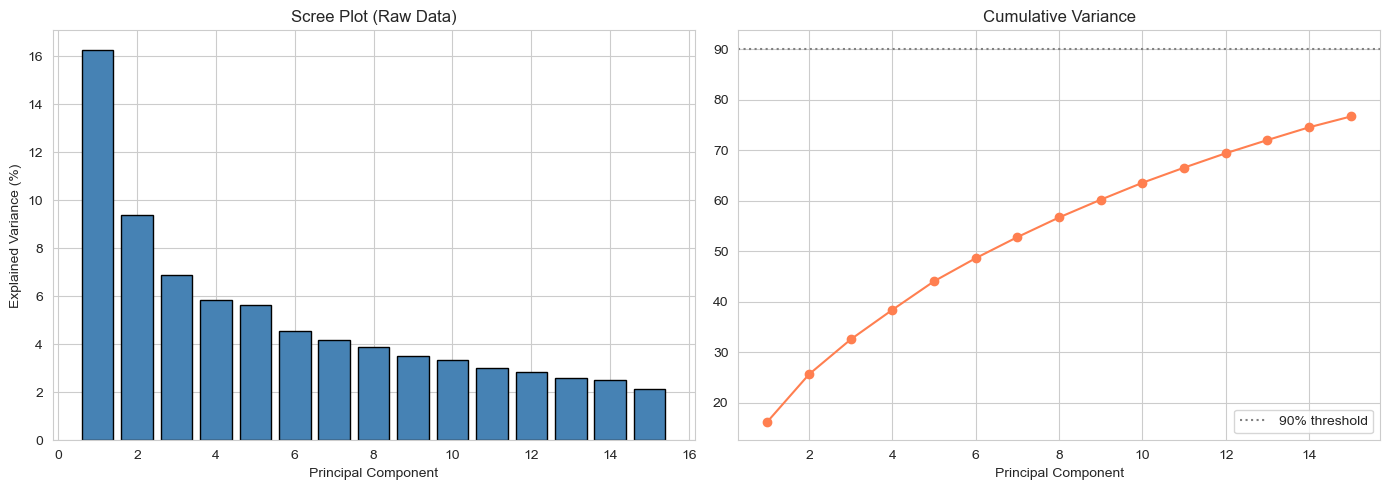

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot explained variance
n_components_show = min(15, len(explained_variance))
axes[0].bar(range(1, n_components_show + 1), explained_variance[:n_components_show] * 100, 
        color='steelblue', edgecolor='black')
axes[0].set_title(f"Scree Plot ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'} Data)")
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')

# Plot cumulative variance
axes[1].plot(range(1, n_components_show + 1), cumulative_variance[:n_components_show] * 100, 
         'o-', color='coral')
axes[1].axhline(y=90, color='gray', linestyle=':', label='90% threshold')
axes[1].set_title('Cumulative Variance')
axes[1].set_xlabel('Principal Component')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Temporal Patterns (PC Scores over Time)

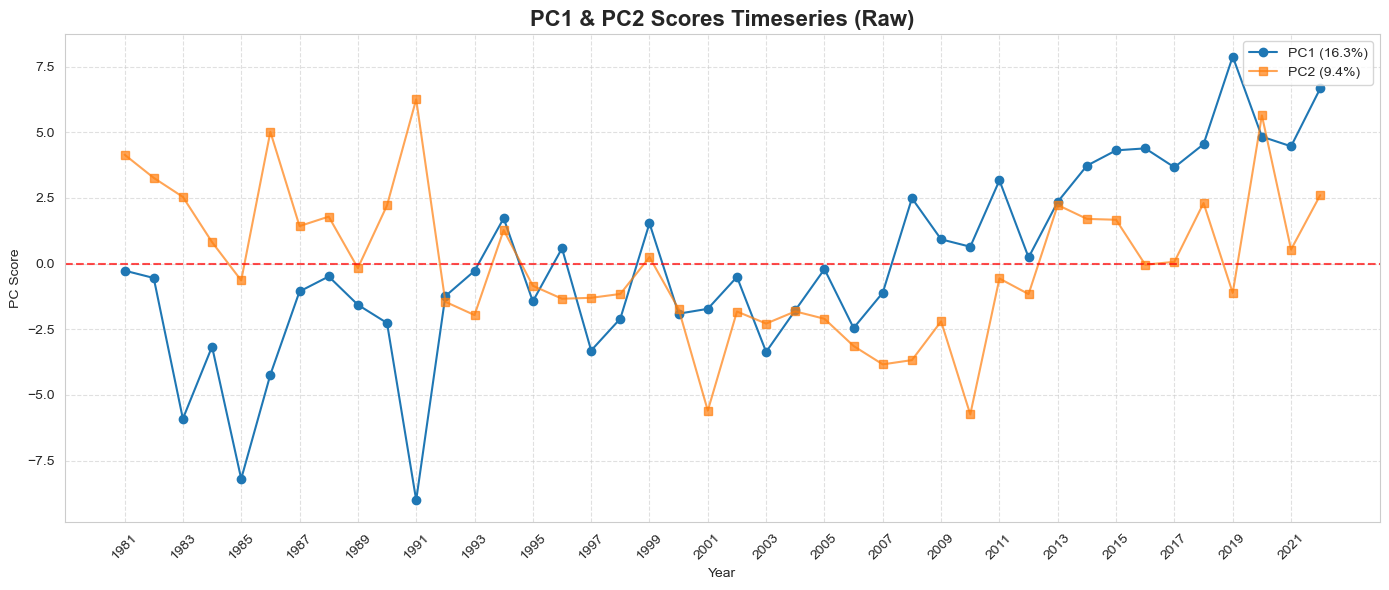

In [8]:
# Plot the temporal evolution of the first 3 PCs
plt.figure(figsize=(14, 6))

# PC1
plt.plot(scores_df.index, scores_df['PC1'], label=f'PC1 ({explained_variance[0]*100:.1f}%)', marker='o')
# PC2
plt.plot(scores_df.index, scores_df['PC2'], label=f'PC2 ({explained_variance[1]*100:.1f}%)', marker='s', alpha=0.7)

plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.title(f"PC1 & PC2 Scores Timeseries ({'Standardized' if USE_STANDARDIZED_DATA else 'Raw'})", fontsize=16, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("PC Score")
plt.xticks(scores_df.index[::2], rotation=45) # Show every 2nd year labels
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Spatial Patterns (PC Loadings)

The loadings show how each station contributes to each principal component.

In [10]:
# Get loadings (components)
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_ready_df.index,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print(f"Loadings shape: {loadings.shape}\n")

# --- PC1 Summary ---
pc1_top10_high = loadings['PC1'].nlargest(10).reset_index()
pc1_top10_high.columns = ['Station_ID', 'PC1_Loading']
pc1_top10_high['Rank'] = range(1, 11)
pc1_top10_high['Type'] = 'Highest'

pc1_top10_low = loadings['PC1'].nsmallest(10).reset_index()
pc1_top10_low.columns = ['Station_ID', 'PC1_Loading']
pc1_top10_low['Rank'] = range(1, 11)
pc1_top10_low['Type'] = 'Lowest'

pc1_summary = pd.concat([pc1_top10_high, pc1_top10_low], ignore_index=True)
pc1_summary = pc1_summary[['Rank', 'Type', 'Station_ID', 'PC1_Loading']]

# --- PC2 Summary ---
pc2_top10_high = loadings['PC2'].nlargest(10).reset_index()
pc2_top10_high.columns = ['Station_ID', 'PC2_Loading']
pc2_top10_high['Rank'] = range(1, 11)
pc2_top10_high['Type'] = 'Highest'

pc2_top10_low = loadings['PC2'].nsmallest(10).reset_index()
pc2_top10_low.columns = ['Station_ID', 'PC2_Loading']
pc2_top10_low['Rank'] = range(1, 11)
pc2_top10_low['Type'] = 'Lowest'

pc2_summary = pd.concat([pc2_top10_high, pc2_top10_low], ignore_index=True)
pc2_summary = pc2_summary[['Rank', 'Type', 'Station_ID', 'PC2_Loading']]

# --- Display Tables ---
print("=" * 50)
print("PC1: Top 10 Highest & Lowest Loading Stations")
print("=" * 50)
display(pc1_summary.style.format({'PC1_Loading': '{:.4f}'}).hide(axis='index'))

print("\n" + "=" * 50)
print("PC2: Top 10 Highest & Lowest Loading Stations")
print("=" * 50)
display(pc2_summary.style.format({'PC2_Loading': '{:.4f}'}).hide(axis='index'))

Loadings shape: (121, 42)

PC1: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC1_Loading
1,Highest,00040620,0.3309
2,Highest,00040636,0.3206
3,Highest,00040617,0.3047
4,Highest,00040632,0.2641
5,Highest,00028153,0.2290
6,Highest,00028169,0.2163
7,Highest,00028143,0.2027
8,Highest,00044594,0.1966
9,Highest,00028150,0.1894
10,Highest,00040715,0.1837



PC2: Top 10 Highest & Lowest Loading Stations


Rank,Type,Station_ID,PC2_Loading
1,Highest,00002823,0.4416
2,Highest,00040632,0.1671
3,Highest,00002811,0.1621
4,Highest,00040620,0.1532
5,Highest,00002725,0.1150
6,Highest,00040636,0.1097
7,Highest,00040714,0.1054
8,Highest,00040617,0.0895
9,Highest,00000275,0.0825
10,Highest,00037181,0.0712


## Stations Eigenvectors

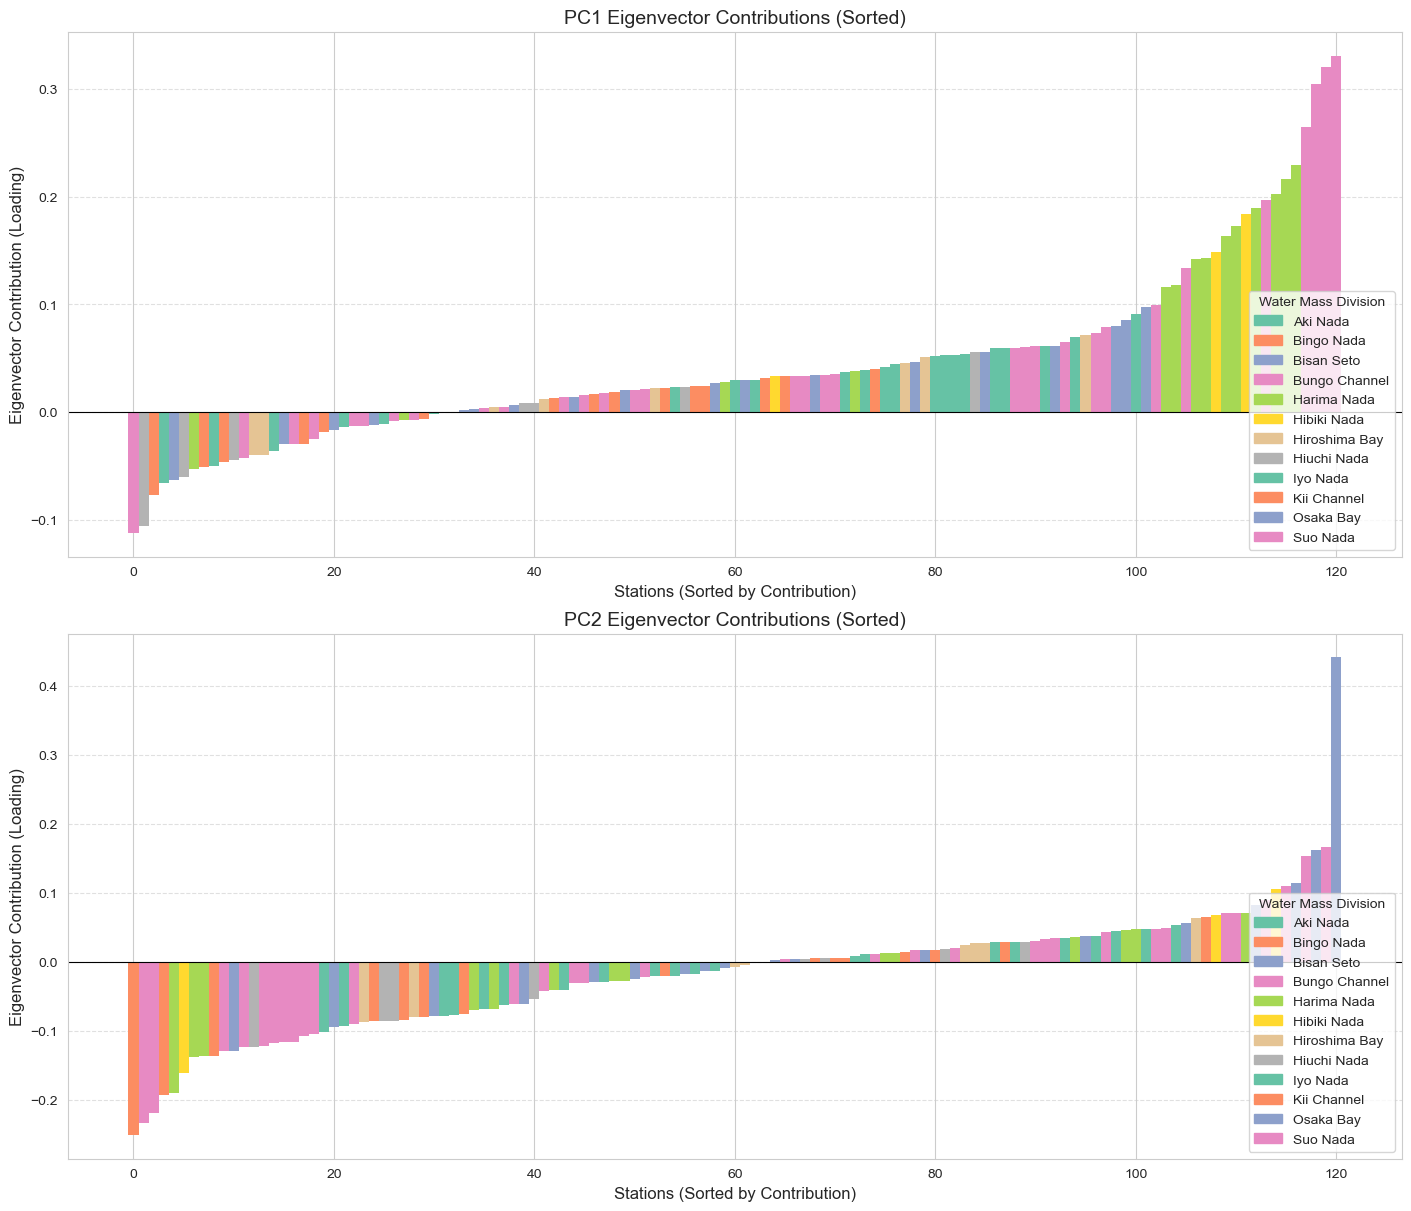

In [21]:
# 6. Eigenvector Contribution Analysis (PC1 & PC2) by Station

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd

# 1. Load Station Division Data
merged_gdf_path = ProjectPaths.PROCESSED_DATA_DIR / "merged_gdf.feather"
if merged_gdf_path.exists():
    merged_gdf = pd.read_feather(merged_gdf_path)
    
    # Check if 'Station' column exists, otherwise use 'zettaicode'
    station_col = 'Station' if 'Station' in merged_gdf.columns else 'zettaicode'
    
    # Ensure Station ID is treated as zfilled string to match PCA index
    merged_gdf[station_col] = merged_gdf[station_col].astype(str).str.zfill(8)
    
    # Create mapping dictionary: Station ID -> Division
    division_map = merged_gdf.drop_duplicates(station_col).set_index(station_col)['division'].to_dict()
else:
    print("Warning: merged_gdf.feather not found. Divisions will be unknown.")
    division_map = {}

# 2. Extract Eigenvectors (Loadings) for PC1 and PC2
# Use pca_ready_df.index because in your PCA prep, features (stations) were rows of original df
loadings_df = pd.DataFrame(
    pca.components_[:2, :].T, 
    columns=['PC1', 'PC2'], 
    index=pca_ready_df.index  # CORRECTED: Use .index (stations) instead of .columns (years)
)

# 3. Add Division Info
loadings_df['division'] = loadings_df.index.map(division_map).fillna('Unknown')

# 4. Define Color Palette for Divisions
unique_divisions = sorted(loadings_df['division'].unique())
palette = sns.color_palette("Set2", len(unique_divisions))
color_map = dict(zip(unique_divisions, palette))

# 5. Plotting Function
def plot_eigenvector_contribution(ax, component, title):
    # Sort data by the specific component's loading value
    data = loadings_df.sort_values(by=component)
    
    # Map colors
    colors = [color_map[d] for d in data['division']]
    
    # Create Bar Plot
    ax.bar(range(len(data)), data[component], color=colors, width=1.0, edgecolor='none')
    
    # Styling
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Eigenvector Contribution (Loading)', fontsize=12)
    ax.set_xlabel('Stations (Sorted by Contribution)', fontsize=12)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='-')
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    
    # Create Custom Legend
    legend_patches = [mpatches.Patch(color=color_map[d], label=d) for d in unique_divisions]
    ax.legend(handles=legend_patches, title='Water Mass Division', loc='lower right', fontsize=10)

# Create Subplots
fig, axes = plt.subplots(2, 1, figsize=(14, 12), constrained_layout=True)

plot_eigenvector_contribution(axes[0], 'PC1', 'PC1 Eigenvector Contributions (Sorted)')
plot_eigenvector_contribution(axes[1], 'PC2', 'PC2 Eigenvector Contributions (Sorted)')

plt.show()

## Plot the station's eigenvector contribution

Merge Result: 121 stations matched out of 121 PCA stations.


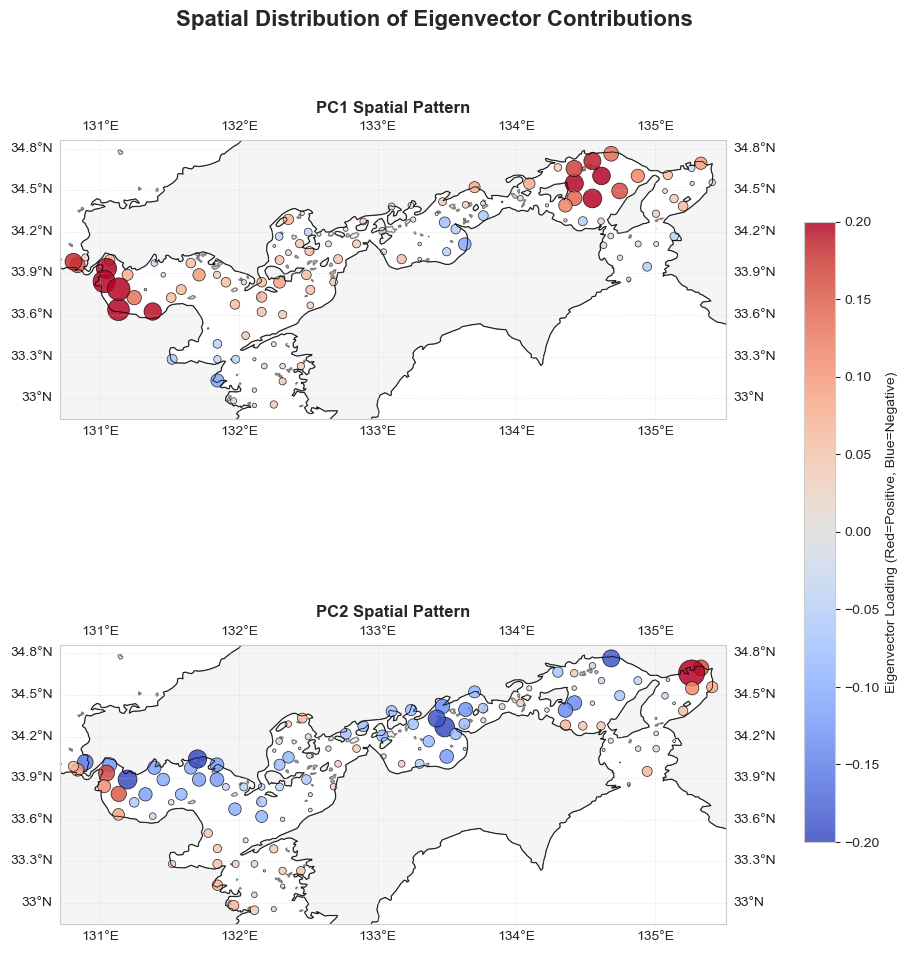

In [48]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Get Eigenvectors (Loadings)
pc1_loadings = pca.components_[0]
pc2_loadings = pca.components_[1]

# 2. Get Station Coordinates
gdf_path = ProjectPaths.PROCESSED_DATA_DIR / "merged_gdf.feather"
gdf = gpd.read_feather(gdf_path)

# 3. Create loadings DataFrame
station_ids = pca_ready_df.index.tolist()

loadings_df = pd.DataFrame({
    'zettaicode': station_ids,
    'PC1_Loading': pc1_loadings,
    'PC2_Loading': pc2_loadings
})

gdf_unique_stations = gdf.drop_duplicates(subset='zettaicode')[['zettaicode', 'geometry']].copy()
loadings_df['zettaicode'] = loadings_df['zettaicode'].astype(str)
gdf_unique_stations['zettaicode'] = gdf_unique_stations['zettaicode'].astype(str)
loadings_map_data = gdf_unique_stations.merge(loadings_df, on='zettaicode', how='inner')

print(f"Merge Result: {len(loadings_map_data)} stations matched out of {len(station_ids)} PCA stations.")

# 4. Plotting (Vertical Stack)
fig, axes = plt.subplots(2, 1, figsize=(10, 12), subplot_kw={'projection': ccrs.PlateCarree()})

# Title closer to the top plot (y=0.95 instead of default ~1.0)
fig.suptitle('Spatial Distribution of Eigenvector Contributions', fontsize=16, fontweight='bold', y=0.95)

components = [('PC1_Loading', 'PC1'), ('PC2_Loading', 'PC2')]

for ax, (col, title) in zip(axes, components):
    pad = 0.1
    min_lon, min_lat, max_lon, max_lat = loadings_map_data.total_bounds
    ax.set_extent([min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad], crs=ccrs.PlateCarree())

    ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)

    sc = ax.scatter(
        loadings_map_data.geometry.x,
        loadings_map_data.geometry.y,
        c=loadings_map_data[col],
        s=loadings_map_data[col].abs() * 800,
        cmap='coolwarm',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        vmin=-0.2, vmax=0.2
    )
    ax.set_title(f'{title} Spatial Pattern', fontsize=12, fontweight='bold')

# Reduce vertical spacing between subplots
plt.subplots_adjust(hspace=0.08, top=0.92)

# Colorbar shifted further right (increased pad from 0.02 to 0.05)
cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.04, pad=0.1)
cbar.set_label('Eigenvector Loading (Red=Positive, Blue=Negative)')

plt.show()

## 7. Summary Statistics

In [22]:
# Determine number of PCs needed for 80% and 90% variance
n_80 = np.argmax(cumulative_variance >= 0.80) + 1
n_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("=" * 50)
print("PCA ANALYSIS SUMMARY")
print("=" * 50)
print(f"Total stations analyzed: {len(pca_ready_df)}")
print(f"Total years: {len(pca_ready_df.columns)}")
print(f"\nVariance explained by PC1: {explained_variance[0]*100:.2f}%")
print(f"Variance explained by PC2: {explained_variance[1]*100:.2f}%")
print(f"Variance explained by PC3: {explained_variance[2]*100:.2f}%")
print(f"\nComponents needed for 80% variance: {n_80}")
print(f"Components needed for 90% variance: {n_90}")
print("=" * 50)

PCA ANALYSIS SUMMARY
Total stations analyzed: 121
Total years: 42

Variance explained by PC1: 16.26%
Variance explained by PC2: 9.39%
Variance explained by PC3: 6.90%

Components needed for 80% variance: 17
Components needed for 90% variance: 24


# Interpretation

The current hypothesis is that the stations with a high decorrelation scale will have an opposite yearly trend compared to the stations with a low decorrelation scale. Let's test this.

In [12]:
# Merge PCA loadings with decorrelation scale data
# First, ensure loadings dataframe has station IDs as index
loadings_analysis = loadings[['PC1', 'PC2', 'PC3']].copy()
loadings_analysis.index.name = 'Station_ID'

# Load decorrelation data if not already loaded
decorrelation_df = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / "stations_decorrelation_scale.csv")
decorrelation_df['Station_ID'] = decorrelation_df['Station_ID'].astype(str).str.zfill(8)
decorrelation_df = decorrelation_df.set_index('Station_ID')

# Merge
analysis_df = loadings_analysis.join(decorrelation_df['Decorrelation_Scale_km'], how='inner')
print(f"Stations with both PCA loadings and decorrelation scale: {len(analysis_df)}")
analysis_df.head()

Stations with both PCA loadings and decorrelation scale: 121


,PC1,PC2,PC3,Decorrelation_Scale_km
Station_ID,,,,
00000275,0.027105,0.082516,-0.099332,10.527210
00002725,-0.011927,0.115002,-0.098616,9.341977
00002737,0.061759,0.057463,0.077463,6.115805
00002744,0.046719,0.004915,0.015811,6.177029
00002750,0.014548,-0.028921,0.027417,6.529284


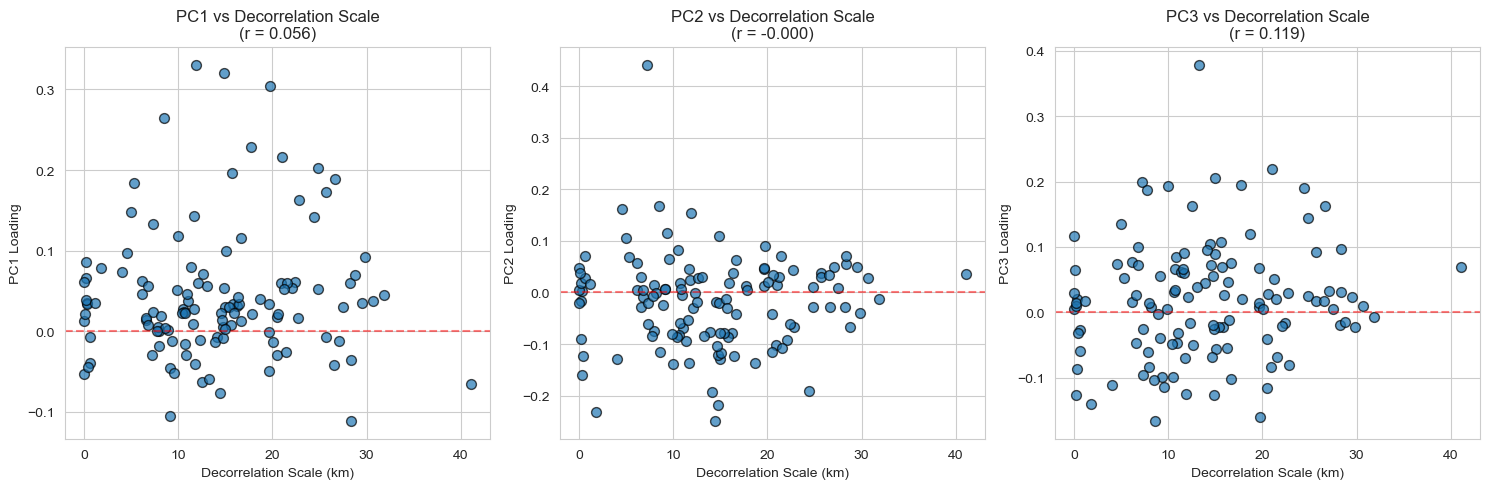

In [13]:
# Scatter plots: Decorrelation Scale vs PC Loadings
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    
    ax.scatter(analysis_df['Decorrelation_Scale_km'], analysis_df[pc_col], 
               alpha=0.7, edgecolor='black', s=50)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    
    # Calculate correlation
    corr = analysis_df['Decorrelation_Scale_km'].corr(analysis_df[pc_col])
    ax.set_xlabel('Decorrelation Scale (km)')
    ax.set_ylabel(f'{pc_col} Loading')
    ax.set_title(f'{pc_col} vs Decorrelation Scale\n(r = {corr:.3f})')
    
plt.tight_layout()
plt.show()

In [16]:
# Divide stations into extreme groups: bottom 25% vs top 25% of decorrelation scale
# This focuses on stations at the extremes for a more meaningful comparison
q25 = analysis_df['Decorrelation_Scale_km'].quantile(0.25)
q75 = analysis_df['Decorrelation_Scale_km'].quantile(0.75)
print(f"25th percentile decorrelation scale: {q25:.2f} km")
print(f"75th percentile decorrelation scale: {q75:.2f} km")

# Create groups - only include extreme stations (bottom 25% and top 25%)
def assign_extreme_group(val):
    if val <= q25:
        return 'Low (≤ 25th pctl)'
    elif val >= q75:
        return 'High (≥ 75th pctl)'
    else:
        return 'Middle (excluded)'

analysis_df['Scale_Group'] = analysis_df['Decorrelation_Scale_km'].apply(assign_extreme_group)

# Filter to only extreme groups for comparison
extreme_df = analysis_df[analysis_df['Scale_Group'] != 'Middle (excluded)'].copy()
print(f"\nNumber of stations in Low group (≤ 25th pctl): {len(extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'])}")
print(f"Number of stations in High group (≥ 75th pctl): {len(extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'])}")

# Compare mean loadings between extreme groups
group_stats = extreme_df.groupby('Scale_Group')[['PC1', 'PC2', 'PC3']].agg(['mean', 'std'])
print("\n=== Mean PC Loadings by Decorrelation Scale Group (Extreme Quartiles) ===")
print(group_stats)

25th percentile decorrelation scale: 7.99 km
75th percentile decorrelation scale: 20.09 km

Number of stations in Low group (≤ 25th pctl): 31
Number of stations in High group (≥ 75th pctl): 31

=== Mean PC Loadings by Decorrelation Scale Group (Extreme Quartiles) ===
                         PC1                PC2                 PC3          
                        mean      std      mean       std      mean       std
Scale_Group                                                                  
High (≥ 75th pctl)  0.048664  0.07992 -0.011702  0.063888  0.025304  0.076945
Low (≤ 25th pctl)   0.036982  0.05517  0.001843  0.113971  0.011058  0.086270


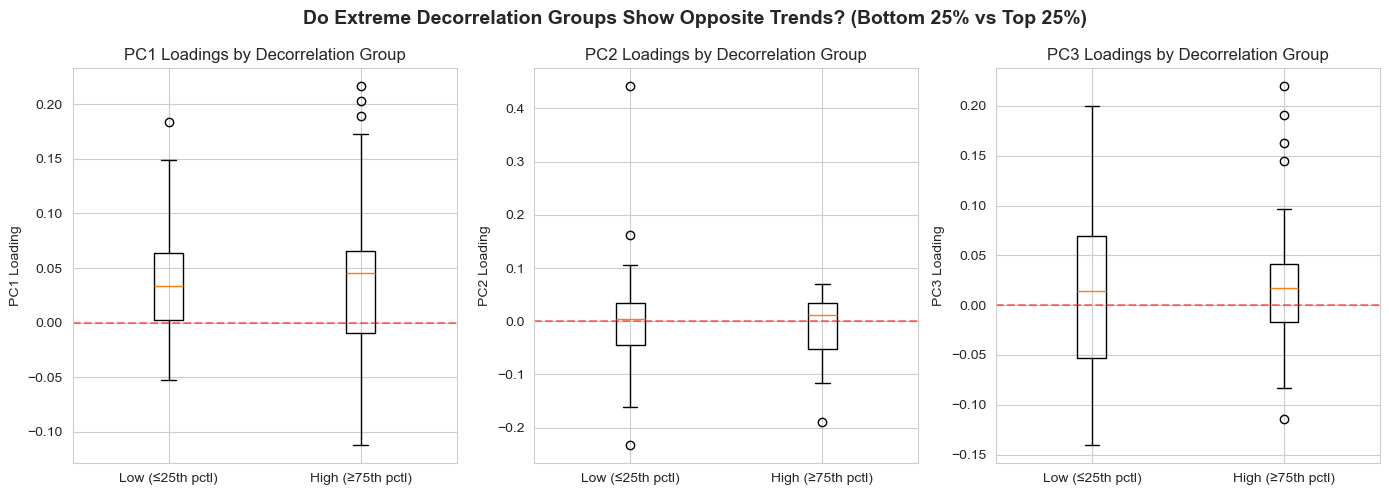

In [17]:
# Box plot comparison of loadings by extreme groups (quartiles)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, ax in enumerate(axes):
    pc_col = f'PC{i+1}'
    
    # Separate data by extreme group (using extreme_df instead of analysis_df)
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    ax.boxplot([low_group, high_group], tick_labels=['Low (≤25th pctl)', 'High (≥75th pctl)'])
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    ax.set_ylabel(f'{pc_col} Loading')
    ax.set_title(f'{pc_col} Loadings by Decorrelation Group')
    
plt.suptitle('Do Extreme Decorrelation Groups Show Opposite Trends? (Bottom 25% vs Top 25%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [19]:
from scipy import stats

# T-test to check if extreme groups have significantly different loadings
print("=== T-Test Results (Extreme Decorrelation Scale Groups: Top 25% vs Bottom 25%) ===\n")

for i in range(3):
    pc_col = f'PC{i+1}'
    
    # Use extreme_df which only contains stations in top 25% and bottom 25%
    high_group = extreme_df[extreme_df['Scale_Group'] == 'High (≥ 75th pctl)'][pc_col]
    low_group = extreme_df[extreme_df['Scale_Group'] == 'Low (≤ 25th pctl)'][pc_col]
    
    t_stat, p_value = stats.ttest_ind(high_group, low_group)
    
    # Check if opposite signs (opposite trends)
    mean_high = high_group.mean()
    mean_low = low_group.mean()
    opposite = (mean_high > 0 and mean_low < 0) or (mean_high < 0 and mean_low > 0)
    
    print(f"{pc_col}:")
    print(f"  Mean (High Scale, ≥75th pctl): {mean_high:.4f}")
    print(f"  Mean (Low Scale, ≤25th pctl):  {mean_low:.4f}")
    print(f"  Opposite signs?    {'YES ✓' if opposite else 'NO'}")
    print(f"  T-statistic: {t_stat:.3f}, p-value: {p_value:.4f}")
    print(f"  Significant (p<0.05)? {'YES ✓' if p_value < 0.05 else 'NO'}")
    print()

=== T-Test Results (Extreme Decorrelation Scale Groups: Top 25% vs Bottom 25%) ===

PC1:
  Mean (High Scale, ≥75th pctl): 0.0487
  Mean (Low Scale, ≤25th pctl):  0.0370
  Opposite signs?    NO
  T-statistic: 0.670, p-value: 0.5056
  Significant (p<0.05)? NO

PC2:
  Mean (High Scale, ≥75th pctl): -0.0117
  Mean (Low Scale, ≤25th pctl):  0.0018
  Opposite signs?    YES ✓
  T-statistic: -0.577, p-value: 0.5660
  Significant (p<0.05)? NO

PC3:
  Mean (High Scale, ≥75th pctl): 0.0253
  Mean (Low Scale, ≤25th pctl):  0.0111
  Opposite signs?    NO
  T-statistic: 0.686, p-value: 0.4953
  Significant (p<0.05)? NO



The T-test results doesn't show a significant result between the two groups. From these results it seems that the hypothesis is incorrect. This might suggest that there are other causing factors other than DO.